# 04 — Segmentation and Behavioral Analysis

**Project:** Repeat Purchase Recovery — Olist E-commerce (Brazil)
**Objective:** Identify which customer segments retain best and which show the weakest repeat behaviour — using only first-order observable signals. The goal is to surface actionable targeting criteria that a product or growth team can act on without needing predictive models.
**Data source:** `data/olist.db` — validated layers through Step 6 (materialised mart tables)
**Observation window:** September 2016 – August 2018

---

### What this notebook answers

| # | Question |
|---|---|
| 1 | Which first-purchase categories produce the highest repeat rates? |
| 2 | Does first order value predict repeat behaviour? |
| 3 | Does basket size (items per order) correlate with returning? |
| 4 | Does a bad first review score suppress repeat purchases? |
| 5 | Does delivery speed or a late delivery hurt retention? |
| 6 | Which payment methods correlate with higher repeat rates? |
| 7 | Which states show the strongest and weakest retention? |
| 8 | What are the most actionable business implications? |

> **Baseline for all comparisons:** 90-day right-censored repeat rate = **2.28%** across all 75,387 eligible customers.


## Setup

Connect to the SQLite database and configure chart styling.

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

DB_PATH = "../data/olist.db"
conn = sqlite3.connect(DB_PATH)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.facecolor": "white",
})

C_BLUE    = "#2563EB"
C_ORANGE  = "#EA580C"
C_GREY    = "#94A3B8"
C_GREEN   = "#16A34A"
C_RED     = "#DC2626"
C_PURPLE  = "#7C3AED"
BASELINE_90D = 2.28   # overall 90-day right-censored repeat rate (%)

# Helper: load a single segment dimension from spm_mat
def get_segment(dim, min_customers=0):
    df = pd.read_sql(
        f"""
        SELECT segment_value, customers,
               ROUND(repeat_rate_30d * 100, 2) AS rate_30d_pct,
               ROUND(repeat_rate_90d * 100, 2) AS rate_90d_pct,
               avg_days_to_second_order,
               ROUND(avg_revenue_90d, 2)   AS avg_rev_90d,
               ROUND(avg_revenue_180d, 2)  AS avg_rev_180d
        FROM spm_mat
        WHERE segment_dimension = '{dim}'
          AND customers >= {min_customers}
        ORDER BY customers DESC
        """,
        conn,
    )
    return df

print("Connected to:", DB_PATH)
print(f"Baseline 90-day repeat rate: {BASELINE_90D}%")


Connected to: ../data/olist.db
Baseline 90-day repeat rate: 2.28%


---

## 1. Repeat Rate by First Purchase Category

The product category a customer first buys in is one of the strongest observable predictors of return behaviour. Categories associated with replenishment, lifestyle, or frequent use should show higher repeat rates than categories driven by one-time need purchases (appliances, furniture).

Two views are shown:
- **Volume-weighted view (top 15 categories):** The largest categories by customer count, with their repeat rates. These represent the bulk of the customer base.
- **Rate-ranked view (min 500 customers):** Categories ranked by 90-day repeat rate, filtered to those with enough customers for the rate to be statistically meaningful.


In [2]:
cat_all = get_segment("first_primary_category")

# View 1: top 15 by customer volume
cat_top15 = cat_all.nlargest(15, "customers").copy()
cat_top15 = cat_top15.sort_values("rate_90d_pct")

# View 2: min 500 customers, ranked by repeat rate
cat_rated = cat_all[cat_all["customers"] >= 500].copy()
cat_rated = cat_rated.sort_values("rate_90d_pct", ascending=False).head(15)

print("Top 15 categories by customer volume:")
print(
    cat_top15.sort_values("customers", ascending=False)[
        ["segment_value", "customers", "rate_30d_pct", "rate_90d_pct", "avg_rev_90d"]
    ].to_string(index=False)
)


Top 15 categories by customer volume:
        segment_value  customers  rate_30d_pct  rate_90d_pct  avg_rev_90d
       bed_bath_table       8798          2.82          4.02       139.27
        health_beauty       8368          1.46          2.26       167.54
       sports_leisure       7182          1.79          2.85       153.09
computers_accessories       6305          1.69          2.16       162.03
      furniture_decor       5921          2.63          3.49       147.56
           housewares       5482          1.34          1.74       136.56
        watches_gifts       5299          1.10          1.59       234.35
            telephony       3985          0.99          1.52        95.06
                 auto       3714          1.01          1.64       179.85
                 toys       3658          1.02          1.69       146.67
           cool_stuff       3457          0.69          0.92       196.64
         garden_tools       3328          1.03          1.64       168.75


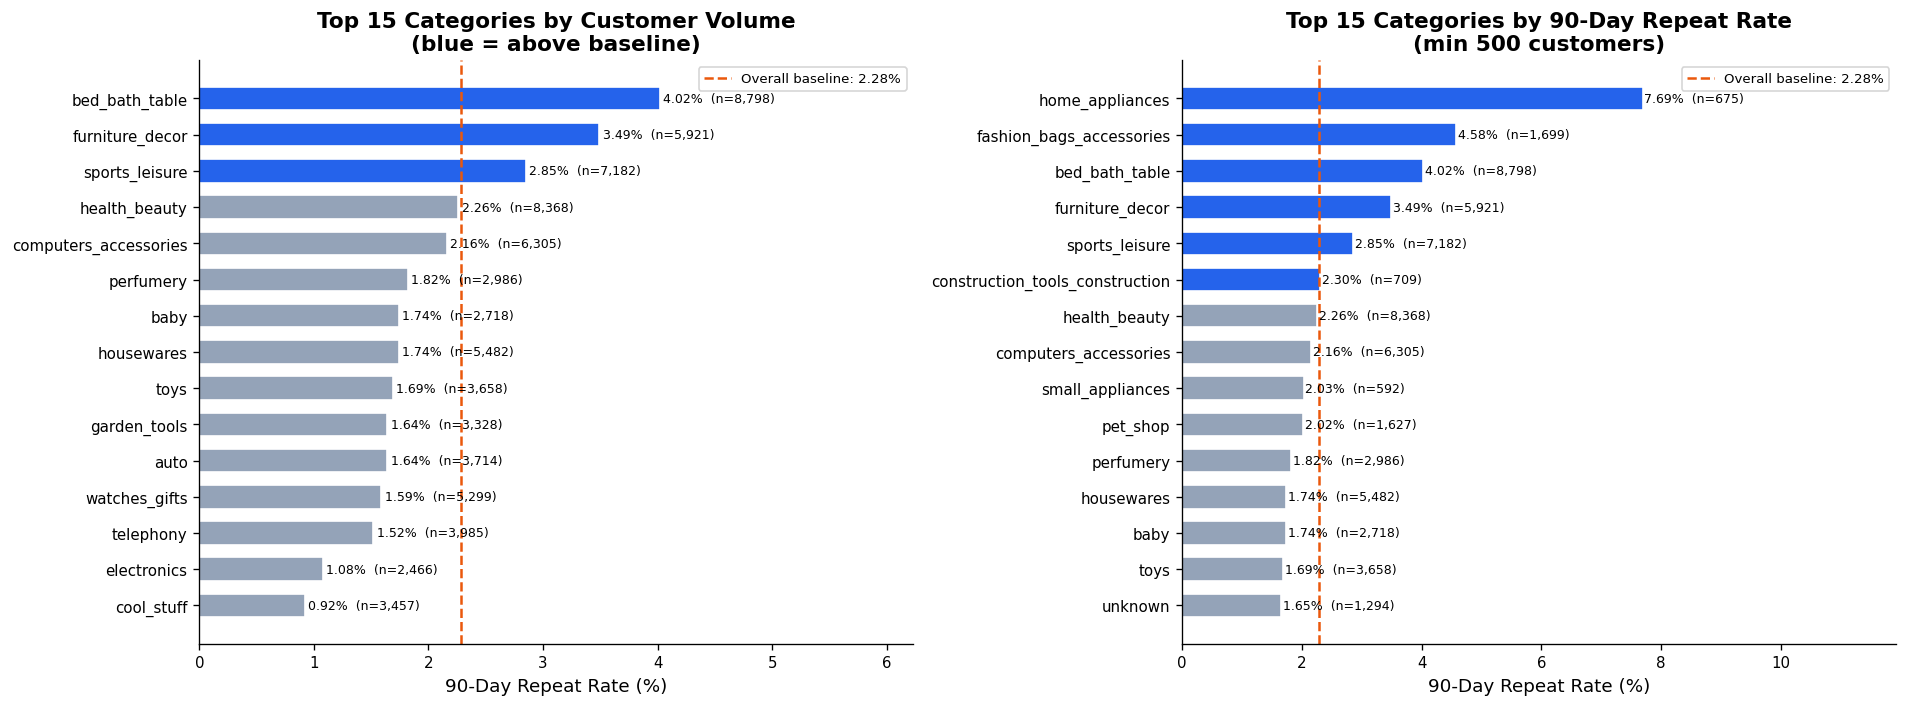

Saved: images/segment_by_category.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Left: top-15 by volume ────────────────────────────────────────────────────
ax1 = axes[0]
colors_vol = [C_BLUE if r >= BASELINE_90D else C_GREY for r in cat_top15["rate_90d_pct"]]
bars1 = ax1.barh(cat_top15["segment_value"], cat_top15["rate_90d_pct"],
                 color=colors_vol, height=0.65, edgecolor="white")
ax1.axvline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")
for bar, row in zip(bars1, cat_top15.itertuples()):
    ax1.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():.2f}%  (n={row.customers:,})",
             va="center", fontsize=7.5)
ax1.set_xlabel("90-Day Repeat Rate (%)")
ax1.set_title("Top 15 Categories by Customer Volume\n(blue = above baseline)")
ax1.legend(fontsize=8)
ax1.set_xlim(0, cat_top15["rate_90d_pct"].max() * 1.55)

# ── Right: top-15 by repeat rate (min 500 customers) ─────────────────────────
ax2 = axes[1]
cat_r = cat_rated.sort_values("rate_90d_pct")
colors_rate = [C_BLUE if r >= BASELINE_90D else C_GREY for r in cat_r["rate_90d_pct"]]
bars2 = ax2.barh(cat_r["segment_value"], cat_r["rate_90d_pct"],
                 color=colors_rate, height=0.65, edgecolor="white")
ax2.axvline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")
for bar, row in zip(bars2, cat_r.itertuples()):
    ax2.text(bar.get_width() + 0.03, bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():.2f}%  (n={row.customers:,})",
             va="center", fontsize=7.5)
ax2.set_xlabel("90-Day Repeat Rate (%)")
ax2.set_title("Top 15 Categories by 90-Day Repeat Rate\n(min 500 customers)")
ax2.legend(fontsize=8)
ax2.set_xlim(0, cat_r["rate_90d_pct"].max() * 1.55)

plt.tight_layout()
plt.savefig("../images/segment_by_category.png", bbox_inches="tight")
plt.show()
print("Saved: images/segment_by_category.png")


**Interpretation:**

**High-repeat categories (above the 2.28% baseline):**
- **`bed_bath_table`** — the largest category (8,798 customers) with the highest repeat rate among high-volume categories at **4.02%**. Linens, towels, and bath accessories are consumable/replenishment products — customers naturally return.
- **`home_appliances`** — a notable outlier at **7.69% (30d: 8.01%)** with an average days-to-second-order of just **21.8 days**. This likely reflects customers returning quickly to the same seller for related products or accessories. Note: n=675, so interpret with some caution.
- **`fashion_bags_accessories`** — **4.58%** repeat rate among 1,699 customers. Fashion accessories are frequently repurchased (seasonal trends, different styles).
- **`furniture_decor`** — **3.49%** among 5,921 customers. Home décor buyers return to build out their spaces.
- **`sports_leisure`** — **2.85%** among 7,182 customers, above baseline.

**Low-repeat categories (below baseline):**
- **`cool_stuff`** and **`electronics`** are below 1.1% — these are discretionary, one-off purchases.
- **`watches_gifts`** — 1.59% repeat rate despite high average order value (R$234). Gift categories attract buyers who complete a one-time transaction and leave.
- **`telephony`** — 1.52%. Mobile accessories/phones are purchased infrequently.

**Business signal:** Category is the strongest single predictor of repeat behaviour in this dataset. Customers who first buy in consumable/lifestyle categories are nearly 2× more likely to return than customers who first buy in one-off categories.


---

## 2. Repeat Rate by First Order Value

Does a high first-order value signal a more engaged customer — one who will come back? Or does a low-value transaction reflect a test purchase that primes the customer to return for more?

This analysis uses the `first_order_value_bucket` dimension from `segment_performance_mart`. Buckets are defined as:
- **Low:** < R$50 (approximately bottom 15th percentile)
- **Mid:** R$50–149 (around the average single-item price)
- **High:** R$150–399 (large single order)
- **Top:** ≥ R$400 (premium or multi-item order)


In [4]:
val_df = get_segment("first_order_value_bucket")
val_df = val_df[val_df["segment_value"] != "null_payment"].copy()

# Define logical sort order
order_map = {"low (<50)": 0, "mid (50-149)": 1, "high (150-399)": 2, "top (400+)": 3}
val_df["sort_order"] = val_df["segment_value"].map(order_map)
val_df = val_df.sort_values("sort_order")

print("Order value segment summary:")
print(
    val_df[["segment_value", "customers", "rate_30d_pct", "rate_90d_pct",
            "avg_days_to_second_order", "avg_rev_90d"]].to_string(index=False)
)


Order value segment summary:
 segment_value  customers  rate_30d_pct  rate_90d_pct  avg_days_to_second_order  avg_rev_90d
     low (<50)      15916          1.71          2.46                      81.1        39.16
  mid (50-149)      47112          1.70          2.40                      76.5        95.87
high (150-399)      24650          1.33          1.98                      94.1       228.96
    top (400+)       5679          1.47          2.04                      63.5       789.44


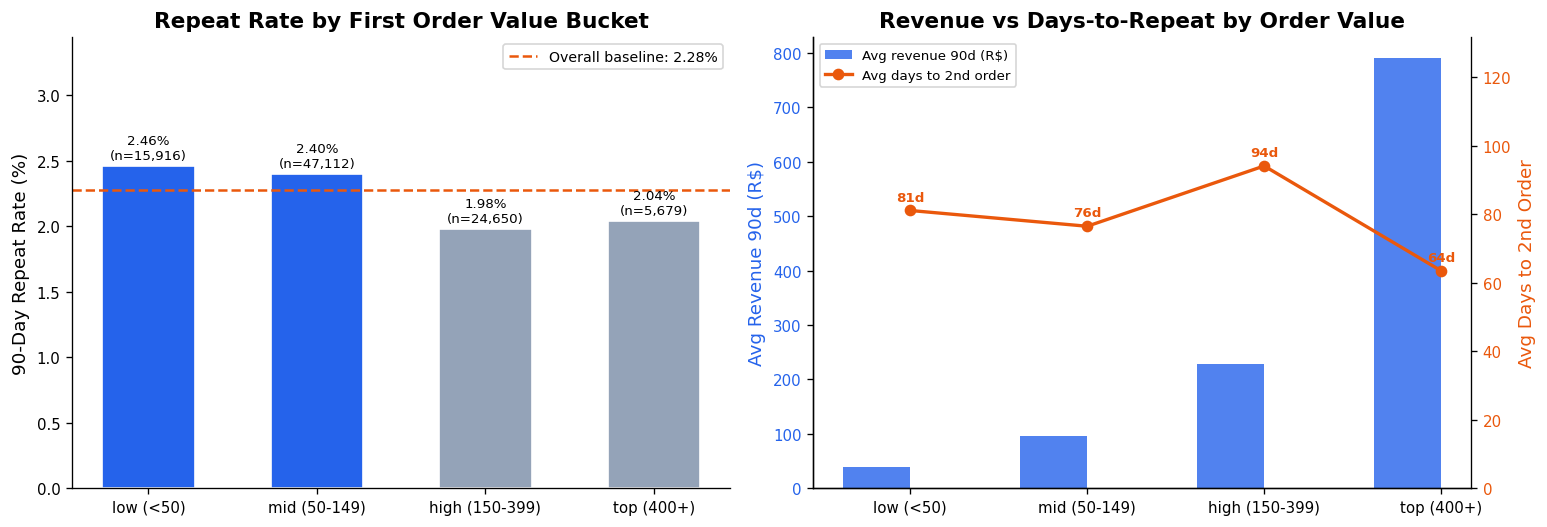

Saved: images/segment_by_order_value.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

labels       = val_df["segment_value"].tolist()
rates_90     = val_df["rate_90d_pct"].tolist()
revenues     = val_df["avg_rev_90d"].tolist()
days         = val_df["avg_days_to_second_order"].tolist()
cust_counts  = val_df["customers"].tolist()

bar_colors = [C_BLUE if r >= BASELINE_90D else C_GREY for r in rates_90]

# ── Left: repeat rate by value bucket ────────────────────────────────────────
ax1 = axes[0]
bars = ax1.bar(labels, rates_90, color=bar_colors, width=0.55, edgecolor="white")
ax1.axhline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")
for bar, rate, n in zip(bars, rates_90, cust_counts):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
             f"{rate:.2f}%\n(n={n:,})", ha="center", va="bottom", fontsize=8)
ax1.set_ylabel("90-Day Repeat Rate (%)")
ax1.set_title("Repeat Rate by First Order Value Bucket")
ax1.set_ylim(0, max(rates_90) * 1.4)
ax1.legend(fontsize=8.5)

# ── Right: avg revenue 90d vs avg days to second order (dual axis) ────────────
ax2 = axes[1]
x = np.arange(len(labels))
bar_w = 0.38

b_rev = ax2.bar(x - bar_w / 2, revenues, width=bar_w, color=C_BLUE,
                alpha=0.8, label="Avg revenue 90d (R$)")
ax2.set_ylabel("Avg Revenue 90d (R$)", color=C_BLUE)
ax2.tick_params(axis="y", labelcolor=C_BLUE)

ax3 = ax2.twinx()
ax3.plot(x, days, color=C_ORANGE, linewidth=2, marker="o", markersize=6,
         label="Avg days to 2nd order")
for xi, d in zip(x, days):
    ax3.text(xi, d + 2, f"{d:.0f}d", ha="center", va="bottom",
             fontsize=8, color=C_ORANGE, fontweight="bold")
ax3.set_ylabel("Avg Days to 2nd Order", color=C_ORANGE)
ax3.tick_params(axis="y", labelcolor=C_ORANGE)
ax3.spines["right"].set_visible(True)
ax3.spines["top"].set_visible(False)
ax3.set_ylim(0, max(days) * 1.4)

ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.set_title("Revenue vs Days-to-Repeat by Order Value")

lines1, labs1 = ax2.get_legend_handles_labels()
lines2, labs2 = ax3.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labs1 + labs2, fontsize=8, loc="upper left")

plt.tight_layout()
plt.savefig("../images/segment_by_order_value.png", bbox_inches="tight")
plt.show()
print("Saved: images/segment_by_order_value.png")


**Interpretation:**

The relationship between first-order value and repeat rate is **not linear** — and the direction is counterintuitive:

- **Low-value buyers (< R$50)** have a **2.46%** 90-day repeat rate — slightly above the overall baseline and higher than both the high and top buckets.
- **Mid-value buyers (R$50–149)** have the highest volume (47,112 customers) and a **2.40%** repeat rate.
- **High-value buyers (R$150–399)** have a **1.98%** repeat rate — below baseline.
- **Top-value buyers (≥ R$400)** have a **2.04%** repeat rate — also below baseline.

**Why?** Several explanations are consistent with the data:
1. **Low-value first purchases are exploratory / test purchases.** The customer was uncertain about the platform, bought something cheap to test it, and then returned when satisfied.
2. **High-value first purchases are often one-time big-ticket items** (appliances, electronics, furniture) that have long replacement cycles. These buyers are satisfied but have no immediate reason to return.
3. **Revenue paradox:** Although high-value buyers repeat less often, their 90-day average revenue is far higher (R$789 for top vs R$39 for low). Each conversion matters more economically, even if it's rarer.

**Days to second order:** Top-value buyers return fastest (**64 days**), while high-value buyers take the longest (**94 days**). Low-value and mid-value buyers are mid-range (~76–81 days).

**Business implication:** Treat low and mid-value first-time buyers as high-potential returners — they represent the largest customer pool and repeat at or above baseline. High-value buyers need longer-horizon re-engagement strategies.


---

## 3. Repeat Rate by First Order Basket Size

Does placing a larger first order — buying more items in a single transaction — predict a higher likelihood of returning? This uses `first_total_items_bucket` from `segment_performance_mart`.

Intuition: customers who buy multiple items in their first order are more engaged with the platform and more likely to have found it valuable. They may also have broader category exposure, increasing their reasons to return.


In [6]:
basket_df = get_segment("first_total_items_bucket")
order_map2 = {"1 item": 0, "2 items": 1, "3-5 items": 2, "6+ items": 3}
basket_df["sort_order"] = basket_df["segment_value"].map(order_map2)
basket_df = basket_df.sort_values("sort_order")

print("Basket size segment summary:")
print(
    basket_df[["segment_value", "customers", "rate_30d_pct", "rate_90d_pct",
               "avg_days_to_second_order", "avg_rev_90d"]].to_string(index=False)
)


Basket size segment summary:
segment_value  customers  rate_30d_pct  rate_90d_pct  avg_days_to_second_order  avg_rev_90d
       1 item      84151          1.49          2.15                      83.0       153.57
      2 items       7101          2.32          3.15                      73.8       216.32
    3-5 items       1871          2.84          4.10                      66.1       343.26
     6+ items        235          5.00          5.38                      34.8       706.60


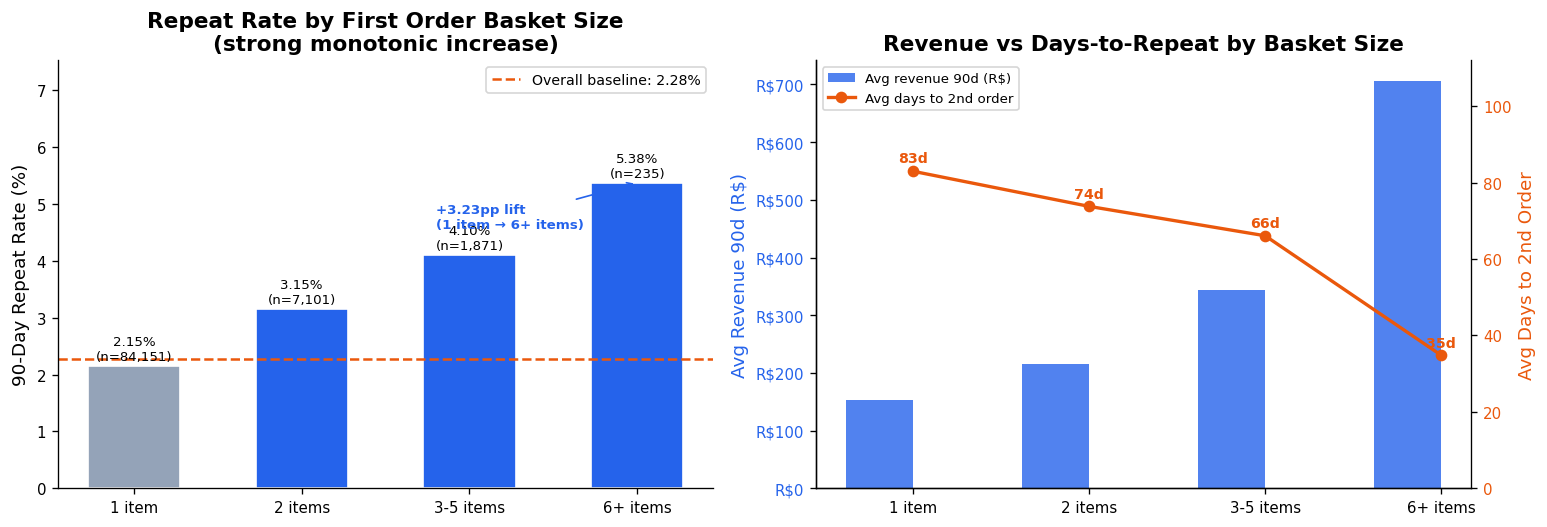

Saved: images/segment_by_basket_size.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

labels_b = basket_df["segment_value"].tolist()
rates_b  = basket_df["rate_90d_pct"].tolist()
days_b   = basket_df["avg_days_to_second_order"].tolist()
rev_b    = basket_df["avg_rev_90d"].tolist()
cust_b   = basket_df["customers"].tolist()
x_b      = np.arange(len(labels_b))

bar_colors_b = [C_BLUE if r >= BASELINE_90D else C_GREY for r in rates_b]

# ── Left: repeat rate monotonic chart ────────────────────────────────────────
ax1 = axes[0]
bars = ax1.bar(x_b, rates_b, color=bar_colors_b, width=0.55, edgecolor="white")
ax1.axhline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")

for bar, rate, n in zip(bars, rates_b, cust_b):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
             f"{rate:.2f}%\n(n={n:,})", ha="center", va="bottom", fontsize=8)

ax1.set_xticks(x_b)
ax1.set_xticklabels(labels_b)
ax1.set_ylabel("90-Day Repeat Rate (%)")
ax1.set_title("Repeat Rate by First Order Basket Size\n(strong monotonic increase)")
ax1.set_ylim(0, max(rates_b) * 1.4)
ax1.legend(fontsize=8.5)

# Annotate the lift
ax1.annotate(
    f"+{rates_b[-1]-rates_b[0]:.2f}pp lift\n(1 item → 6+ items)",
    xy=(x_b[-1], rates_b[-1]),
    xytext=(x_b[-1] - 1.2, rates_b[-1] * 0.85),
    fontsize=8, color=C_BLUE, fontweight="bold",
    arrowprops=dict(arrowstyle="->", color=C_BLUE, lw=1.0),
)

# ── Right: revenue and days side by side ──────────────────────────────────────
ax2 = axes[1]
bar_w = 0.38
ax2.bar(x_b - bar_w / 2, rev_b, width=bar_w, color=C_BLUE, alpha=0.8,
        label="Avg revenue 90d (R$)")
ax2.set_ylabel("Avg Revenue 90d (R$)", color=C_BLUE)
ax2.tick_params(axis="y", labelcolor=C_BLUE)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R${int(x):,}"))

ax3 = ax2.twinx()
ax3.plot(x_b, days_b, color=C_ORANGE, linewidth=2, marker="o", markersize=6,
         label="Avg days to 2nd order")
for xi, d in zip(x_b, days_b):
    ax3.text(xi, d + 1.5, f"{d:.0f}d", ha="center", va="bottom",
             fontsize=8.5, color=C_ORANGE, fontweight="bold")
ax3.set_ylabel("Avg Days to 2nd Order", color=C_ORANGE)
ax3.tick_params(axis="y", labelcolor=C_ORANGE)
ax3.spines["right"].set_visible(True)
ax3.spines["top"].set_visible(False)
ax3.set_ylim(0, max(days_b) * 1.35)

ax2.set_xticks(x_b)
ax2.set_xticklabels(labels_b)
ax2.set_title("Revenue vs Days-to-Repeat by Basket Size")

l1, n1 = ax2.get_legend_handles_labels()
l2, n2 = ax3.get_legend_handles_labels()
ax2.legend(l1 + l2, n1 + n2, fontsize=8, loc="upper left")

plt.tight_layout()
plt.savefig("../images/segment_by_basket_size.png", bbox_inches="tight")
plt.show()
print("Saved: images/segment_by_basket_size.png")


**Interpretation:**

Basket size shows the **clearest monotonic signal** of all segmentation dimensions in this notebook:

| Basket Size | 90d Repeat Rate | Avg Revenue 90d | Avg Days to 2nd Order |
|-------------|----------------|-----------------|----------------------|
| 1 item      | 2.15%          | R$154           | 83 days              |
| 2 items     | 3.15%          | R$216           | 74 days              |
| 3–5 items   | 4.10%          | R$343           | 66 days              |
| 6+ items    | 5.38%          | R$707           | 35 days              |

Every additional item in the first order is associated with:
1. **A higher probability of returning** (2.15% → 5.38% = a +3.23 percentage point lift)
2. **More revenue on the next visit** (R$154 → R$707)
3. **A shorter return interval** (83 days → 35 days)

The triple combination — higher rate, higher value, faster return — makes the 6+ item segment the most valuable customer profile in the dataset, despite being the smallest group (n=235).

**Caution:** The 6+ item segment is small and some of the extreme values may be noisy. But the trend across all four buckets is robust, driven by a 90%+ majority of customers in the 1-item bucket.

**Business implication:** Nudging customers to add even one more item to their first order ("frequently bought together", bundle promotions) would shift a meaningful share from the 2.15% to the 3.15% return rate — a 47% relative improvement in retention for that cohort.


---

## 4. Repeat Rate by First Review Score

A low review score on the first order is a widely assumed churn signal. Does the data support this assumption? This section tests whether customers who left a negative review (1–2 stars) actually returned at lower rates than satisfied customers (4–5 stars).


In [8]:
rev_df = get_segment("first_review_score_bucket")
order_map3 = {"low (1-2)": 0, "mid (3)": 1, "high (4-5)": 2, "no_review": 3}
rev_df["sort_order"] = rev_df["segment_value"].map(order_map3)
rev_df = rev_df.sort_values("sort_order")

print("Review score segment summary:")
print(
    rev_df[["segment_value", "customers", "rate_30d_pct", "rate_90d_pct",
            "avg_days_to_second_order", "avg_rev_90d"]].to_string(index=False)
)


Review score segment summary:
segment_value  customers  rate_30d_pct  rate_90d_pct  avg_days_to_second_order  avg_rev_90d
    low (1-2)      11913          1.75          2.28                      62.2       191.61
      mid (3)       7669          1.67          2.23                      66.8       153.94
   high (4-5)      73161          1.55          2.28                      85.7       159.63
    no_review        615          1.86          2.25                      60.7       203.12


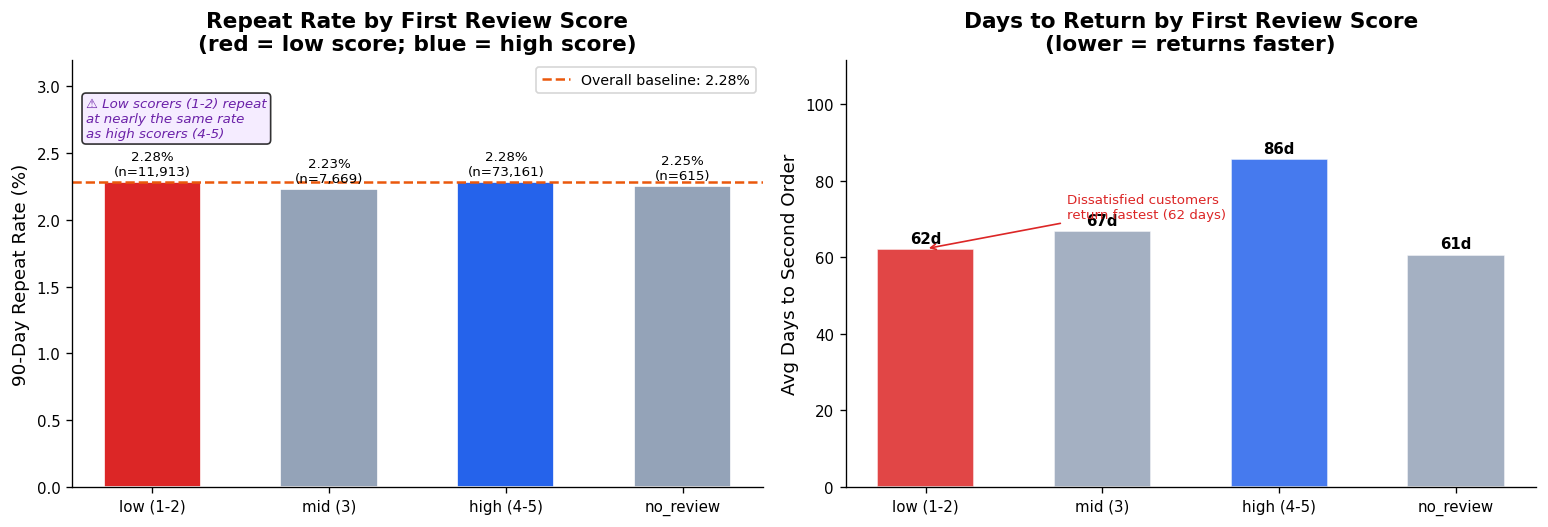

Saved: images/segment_by_review_score.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

labels_r = rev_df["segment_value"].tolist()
rates_r  = rev_df["rate_90d_pct"].tolist()
days_r   = rev_df["avg_days_to_second_order"].tolist()
rev_r    = rev_df["avg_rev_90d"].tolist()
cust_r   = rev_df["customers"].tolist()
x_r      = np.arange(len(labels_r))

review_colors = [C_RED, C_GREY, C_BLUE, C_GREY]

# ── Left: repeat rate by review score ────────────────────────────────────────
ax1 = axes[0]
bars = ax1.bar(x_r, rates_r, color=review_colors, width=0.55, edgecolor="white")
ax1.axhline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")

for bar, rate, n in zip(bars, rates_r, cust_r):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
             f"{rate:.2f}%\n(n={n:,})", ha="center", va="bottom", fontsize=8)

ax1.set_xticks(x_r)
ax1.set_xticklabels(labels_r)
ax1.set_ylabel("90-Day Repeat Rate (%)")
ax1.set_title("Repeat Rate by First Review Score\n(red = low score; blue = high score)")
ax1.set_ylim(0, max(rates_r) * 1.4)
ax1.legend(fontsize=8.5)

# Annotation: counterintuitive finding
ax1.text(0.02, 0.82,
         "⚠ Low scorers (1-2) repeat\nat nearly the same rate\nas high scorers (4-5)",
         transform=ax1.transAxes, fontsize=8, color="#6B21A8",
         style="italic", bbox=dict(boxstyle="round,pad=0.3", facecolor="#F3E8FF", alpha=0.8))

# ── Right: avg days to second order ──────────────────────────────────────────
ax2 = axes[1]
bar_colors_d = [C_RED, C_GREY, C_BLUE, C_GREY]
bars2 = ax2.bar(x_r, days_r, color=bar_colors_d, width=0.55, edgecolor="white", alpha=0.85)

for bar, d, n in zip(bars2, days_r, cust_r):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
             f"{d:.0f}d", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2.set_xticks(x_r)
ax2.set_xticklabels(labels_r)
ax2.set_ylabel("Avg Days to Second Order")
ax2.set_title("Days to Return by First Review Score\n(lower = returns faster)")
ax2.set_ylim(0, max(days_r) * 1.3)

# Annotation: low scorers return faster
ax2.annotate(
    "Dissatisfied customers\nreturn fastest (62 days)",
    xy=(0, days_r[0]), xytext=(0.8, days_r[0] + 8),
    fontsize=8, color=C_RED,
    arrowprops=dict(arrowstyle="->", color=C_RED, lw=1.0),
)

plt.tight_layout()
plt.savefig("../images/segment_by_review_score.png", bbox_inches="tight")
plt.show()
print("Saved: images/segment_by_review_score.png")


**Interpretation — A Counterintuitive Finding:**

The data does **not** support the assumption that a bad first review score suppresses repeat purchases:

| Review Score | 90d Repeat Rate | Avg Days to Return |
|---|---|---|
| Low (1–2 stars) | **2.28%** | **62 days** |
| Mid (3 stars) | 2.23% | 67 days |
| High (4–5 stars) | 2.28% | 86 days |
| No review | 2.25% | 61 days |

**All four groups have nearly identical 90-day repeat rates (2.23%–2.28%).**

Even more striking: customers who left a **1 or 2 star review** return on average in **62 days** — 24 days faster than satisfied customers (86 days). Customers with no review also return quickly at 61 days.

**Why might dissatisfied customers still return?**
1. **Purchasing need overrides sentiment.** The customer may have had a bad experience (delayed delivery, damaged item) but still needs to buy in the category. There are limited alternatives on the platform.
2. **Resolution seekers.** Some customers who gave low scores may return to find a better version of the product or a different seller.
3. **Marketplace dynamics.** In a marketplace, a negative experience with one seller doesn't necessarily mean the customer will leave the platform entirely — they may simply switch sellers.
4. **Measurement limitation.** The churn signal mart flags the *first* order's review. A customer might have a bad experience and still return, but their second-order experience could be better. We're measuring first-order signals against entire-horizon return behaviour.

**Business caution:** This does NOT mean ignoring low review scores. Low scores should still trigger service recovery outreach (a discount, apology, or replacement offer). The data suggests those customers will likely return anyway — but proactive recovery may speed up return and improve LTV even further.


---

## 5. Repeat Rate by Delivery Experience

Two delivery dimensions are analysed:

**5A. Delivery Speed Bucket** — how many days the order took from purchase to delivery (from `segment_performance_mart`):
- Fast (≤ 7 days), Standard (8–14 days), Slow (15–30 days), Very Slow (> 30 days)

**5B. Delivery On-Time vs Late** — whether the order arrived before, on, or after the estimated delivery date (built from `cfpm_mat` + `crsm_mat` since this dimension is not in `segment_performance_mart`):
- Early, On-time Exact, Late


In [10]:
# 5A: delivery speed from spm_mat
speed_df = get_segment("first_delivery_speed_bucket")
speed_df = speed_df[speed_df["segment_value"] != "unknown"].copy()
speed_order = {"fast (<=7d)": 0, "standard (8-14d)": 1, "slow (15-30d)": 2, "very_slow (>30d)": 3}
speed_df["sort_order"] = speed_df["segment_value"].map(speed_order)
speed_df = speed_df.sort_values("sort_order")

print("Delivery speed segments:")
print(speed_df[["segment_value","customers","rate_30d_pct","rate_90d_pct",
                "avg_days_to_second_order","avg_rev_90d"]].to_string(index=False))


Delivery speed segments:
   segment_value  customers  rate_30d_pct  rate_90d_pct  avg_days_to_second_order  avg_rev_90d
     fast (<=7d)      29513          1.57          2.36                      79.2       142.66
standard (8-14d)      36878          1.61          2.33                      85.7       165.38
   slow (15-30d)      22775          1.60          2.18                      77.7       180.40
very_slow (>30d)       4184          1.44          1.96                      72.1       202.67


In [11]:
# 5B: delivery delay (on-time vs late) — built from raw marts
delay_df = pd.read_sql(
    """
    SELECT
        CASE
            WHEN f.first_delivery_delay_days IS NULL THEN 'unknown'
            WHEN f.first_delivery_delay_days > 0      THEN 'late'
            WHEN f.first_delivery_delay_days = 0      THEN 'on_time_exact'
            ELSE                                           'early'
        END AS delay_group,
        COUNT(*)                                                            AS customers,
        ROUND(AVG(CAST(r.repeat_within_30d AS REAL)) * 100, 2)             AS rate_30d_pct,
        ROUND(AVG(CAST(r.repeat_within_90d AS REAL)) * 100, 2)             AS rate_90d_pct,
        ROUND(AVG(CASE WHEN r.days_to_second_order IS NOT NULL
                       THEN r.days_to_second_order END), 1)                 AS avg_days_to_second,
        ROUND(AVG(f.first_delivery_delay_days), 1)                         AS avg_delay_days
    FROM cfpm_mat f
    JOIN crsm_mat r ON f.customer_unique_id = r.customer_unique_id
    WHERE f.first_delivery_delay_days IS NOT NULL
    GROUP BY delay_group
    ORDER BY customers DESC
    """,
    conn,
)

print("\nDelivery delay group segments:")
print(delay_df.to_string(index=False))



Delivery delay group segments:
  delay_group  customers  rate_30d_pct  rate_90d_pct  avg_days_to_second  avg_delay_days
        early      84519          1.59          2.30                82.8           -13.0
         late       7428          1.56          2.05                57.9            10.0
on_time_exact       1403          1.34          2.19                85.7             0.0


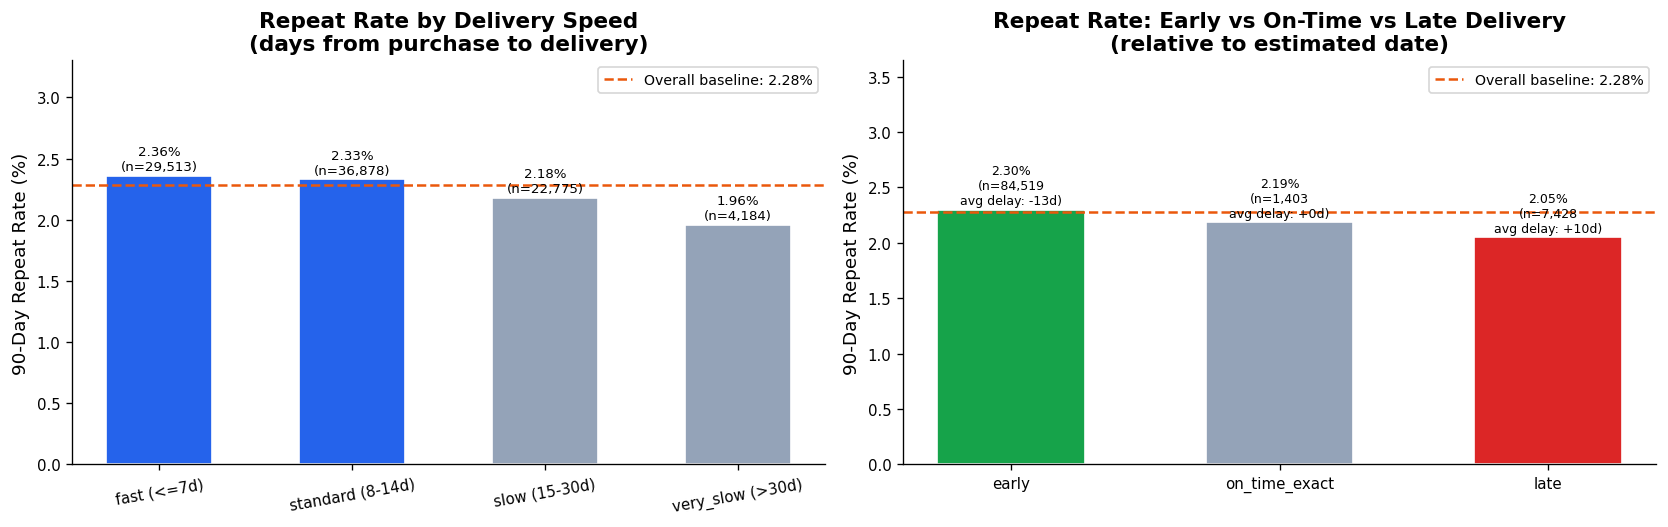

Saved: images/segment_by_delivery.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# ── Left: delivery speed (from spm_mat) ──────────────────────────────────────
ax1 = axes[0]
labels_s = speed_df["segment_value"].tolist()
rates_s  = speed_df["rate_90d_pct"].tolist()
rev_s    = speed_df["avg_rev_90d"].tolist()
cust_s   = speed_df["customers"].tolist()
x_s      = np.arange(len(labels_s))

colors_s = [C_BLUE if r >= BASELINE_90D else C_GREY for r in rates_s]
bars1 = ax1.bar(x_s, rates_s, color=colors_s, width=0.55, edgecolor="white")
ax1.axhline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")

for bar, rate, n in zip(bars1, rates_s, cust_s):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
             f"{rate:.2f}%\n(n={n:,})", ha="center", va="bottom", fontsize=8)

ax1.set_xticks(x_s)
ax1.set_xticklabels(labels_s, rotation=10)
ax1.set_ylabel("90-Day Repeat Rate (%)")
ax1.set_title("Repeat Rate by Delivery Speed\n(days from purchase to delivery)")
ax1.set_ylim(0, max(rates_s) * 1.4)
ax1.legend(fontsize=8.5)

# ── Right: on-time vs late (from cfpm_mat + crsm_mat) ────────────────────────
ax2 = axes[1]
delay_plot = delay_df[delay_df["delay_group"] != "unknown"].copy()
delay_order = {"early": 0, "on_time_exact": 1, "late": 2}
delay_plot["sort_order"] = delay_plot["delay_group"].map(delay_order)
delay_plot = delay_plot.sort_values("sort_order")

delay_colors = [C_GREEN, C_GREY, C_RED]
bars2 = ax2.bar(
    delay_plot["delay_group"], delay_plot["rate_90d_pct"],
    color=delay_colors, width=0.55, edgecolor="white",
)
ax2.axhline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")

for bar, (_, row) in zip(bars2, delay_plot.iterrows()):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{row.rate_90d_pct:.2f}%\n(n={row.customers:,}\navg delay: {row.avg_delay_days:+.0f}d)",
        ha="center", va="bottom", fontsize=7.5,
    )

ax2.set_ylabel("90-Day Repeat Rate (%)")
ax2.set_title("Repeat Rate: Early vs On-Time vs Late Delivery\n(relative to estimated date)")
ax2.set_ylim(0, BASELINE_90D * 1.6)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig("../images/segment_by_delivery.png", bbox_inches="tight")
plt.show()
print("Saved: images/segment_by_delivery.png")


**Interpretation:**

**Delivery Speed (absolute days):**
- Fast (≤ 7 days): **2.36%** — slightly above baseline
- Standard (8–14 days): **2.33%** — at baseline
- Slow (15–30 days): **2.18%** — slightly below baseline
- Very Slow (> 30 days): **1.96%** — below baseline

The effect is real but modest. A **0.40 percentage point spread** between fastest and slowest delivery. Slower deliveries are associated with higher-value orders (avg R$203 for very slow vs R$143 for fast) — suggesting that customers who order expensive, heavy items accept longer waits. These customers may repeat less partly because of product type, not just delivery experience.

**On-Time vs Late (relative to estimated date):**
- **Early (arrived before estimated):** 2.30% — at baseline. Represents 84,519 customers (91% of all customers with a known delivery date).
- **Late (arrived after estimated):** 2.05% — 0.23pp below baseline. Represents 7,428 customers.
- **On-time exact:** 2.19% — at baseline.

A late delivery is associated with a **~11% relative reduction** in the 90-day repeat rate (2.30% early → 2.05% late). The effect is real but not severe — a missed delivery promise damages retention somewhat, but does not stop most customers from returning.

**Combined reading:** Delivery experience matters, but it is not a dominant predictor of repeat behaviour in this dataset. Category, basket size, and order value show stronger effects. That said, 7,428 customers received a late delivery — proactively reaching out to this group (apology, discount on next order) could meaningfully recover some of the 0.23pp gap.


---

## 6. Repeat Rate by First Payment Type

Payment method can act as a proxy for customer intent and financial engagement with the platform:
- **Credit card** customers are the dominant group and may range from casual to engaged buyers
- **Boleto** (bank slip) customers in Brazil often represent unbanked or lower-income segments
- **Voucher** customers specifically sought out a discount — strong price sensitivity signal
- **Debit card** customers pay immediately from their account — suggests more deliberate spending


In [13]:
pay_df = get_segment("first_payment_type")
pay_df = pay_df[pay_df["segment_value"] != "unknown"].copy()
pay_df = pay_df.sort_values("rate_90d_pct", ascending=False)

print("Payment type segment summary:")
print(
    pay_df[["segment_value", "customers", "rate_30d_pct", "rate_90d_pct",
            "avg_days_to_second_order", "avg_rev_90d"]].to_string(index=False)
)


Payment type segment summary:
segment_value  customers  rate_30d_pct  rate_90d_pct  avg_days_to_second_order  avg_rev_90d
      voucher       1409          2.41          3.07                      85.5       108.19
  credit_card      71882          1.56          2.27                      83.1       169.19
       boleto      18625          1.61          2.24                      75.4       147.51
   debit_card       1441          1.71          2.17                      47.8       142.60


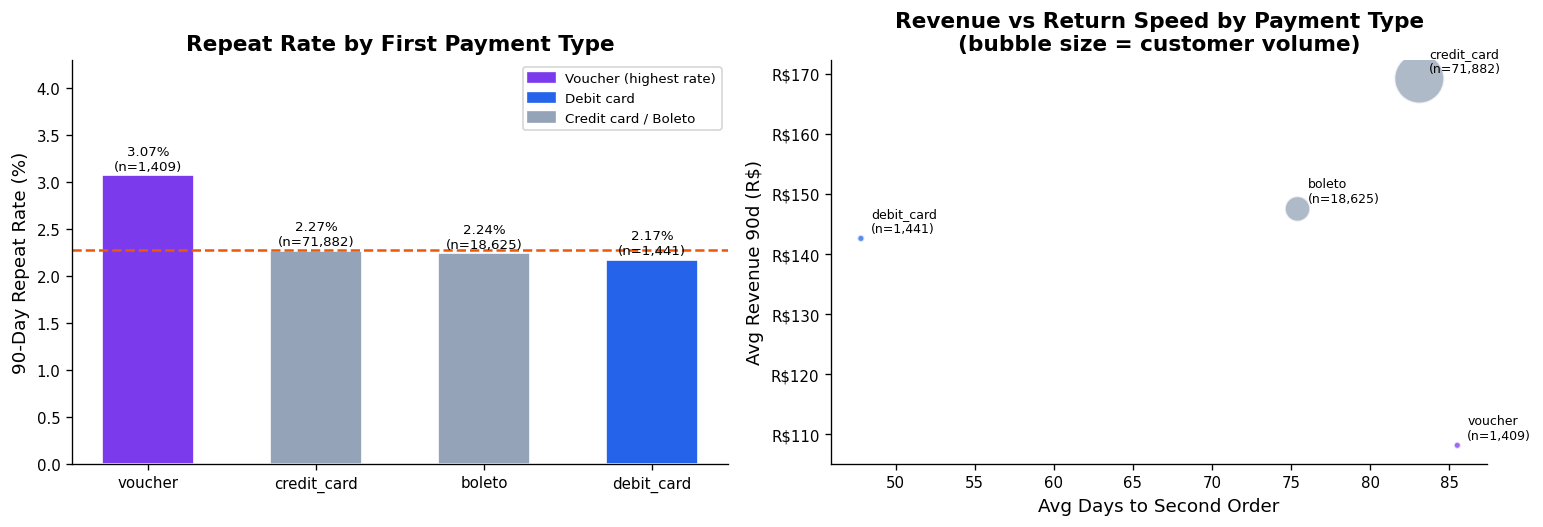

Saved: images/segment_by_payment_type.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

labels_p = pay_df["segment_value"].tolist()
rates_p  = pay_df["rate_90d_pct"].tolist()
days_p   = pay_df["avg_days_to_second_order"].tolist()
rev_p    = pay_df["avg_rev_90d"].tolist()
cust_p   = pay_df["customers"].tolist()
x_p      = np.arange(len(labels_p))

pay_colors = {
    "voucher": C_PURPLE, "debit_card": C_BLUE,
    "boleto": C_GREY, "credit_card": C_GREY,
}
bar_colors_p = [pay_colors.get(lbl, C_GREY) for lbl in labels_p]

# ── Left: repeat rate ────────────────────────────────────────────────────────
ax1 = axes[0]
bars1 = ax1.bar(x_p, rates_p, color=bar_colors_p, width=0.55, edgecolor="white")
ax1.axhline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")
for bar, rate, n in zip(bars1, rates_p, cust_p):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
             f"{rate:.2f}%\n(n={n:,})", ha="center", va="bottom", fontsize=8)

ax1.set_xticks(x_p)
ax1.set_xticklabels(labels_p)
ax1.set_ylabel("90-Day Repeat Rate (%)")
ax1.set_title("Repeat Rate by First Payment Type")
ax1.set_ylim(0, max(rates_p) * 1.4)
ax1.legend(fontsize=8.5)

legend_elements = [
    mpatches.Patch(color=C_PURPLE, label="Voucher (highest rate)"),
    mpatches.Patch(color=C_BLUE, label="Debit card"),
    mpatches.Patch(color=C_GREY, label="Credit card / Boleto"),
]
ax1.legend(handles=legend_elements, fontsize=8, loc="upper right")

# ── Right: revenue vs days bubble chart ──────────────────────────────────────
ax2 = axes[1]
bubble_sizes = [n / 80 for n in cust_p]
scatter_colors = bar_colors_p

sc = ax2.scatter(days_p, rev_p, s=bubble_sizes, c=scatter_colors, alpha=0.75,
                 edgecolors="white", linewidths=1.2)

for xi, yi, lbl, n in zip(days_p, rev_p, labels_p, cust_p):
    ax2.annotate(f"{lbl}\n(n={n:,})", (xi, yi),
                 textcoords="offset points", xytext=(6, 4),
                 fontsize=7.5)

ax2.set_xlabel("Avg Days to Second Order")
ax2.set_ylabel("Avg Revenue 90d (R$)")
ax2.set_title("Revenue vs Return Speed by Payment Type\n(bubble size = customer volume)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R${int(x):,}"))

plt.tight_layout()
plt.savefig("../images/segment_by_payment_type.png", bbox_inches="tight")
plt.show()
print("Saved: images/segment_by_payment_type.png")


**Interpretation:**

| Payment Type | 90d Repeat Rate | Avg Days to Return | Avg Revenue 90d |
|---|---|---|---|
| Voucher | **3.07%** | 86 days | R$108 |
| Debit card | 2.17% | **48 days** | R$143 |
| Boleto | 2.24% | 75 days | R$148 |
| Credit card | 2.27% | 83 days | R$169 |

**Voucher customers have the highest repeat rate (3.07%)**, but the lowest average 90-day revenue (R$108). This suggests voucher customers are:
- Highly price-motivated — they activated because of the discount
- Likely to return when another discount opportunity arises (or when they believe they can find a deal)
- Not necessarily high-value: their revenue per order is lower, and they may only transact when pricing is favourable

**Debit card customers return fastest** (48 days avg) — their deliberate, immediate payment style may reflect stronger purchase intent and willingness to re-engage sooner.

**Credit card customers** dominate in volume (71,882 customers) and have mid-range metrics across all dimensions — they are the reliable core segment.

**Business implication:** Voucher customers are a re-engagement lever — sending them a discount at the 60–90 day mark will likely convert them. However, monitor their lifetime value carefully: if each purchase requires a voucher, the margin impact may not justify the acquisition cost.


---

## 7. Repeat Rate by Geography (Top States)

Brazil has significant regional variation in e-commerce adoption, logistics infrastructure, and purchasing behaviour. This section compares the top 15 states by customer volume to identify geographic pockets of stronger or weaker retention.

> **Note on small states:** States with fewer than 100 customers are excluded from this analysis. Their small sample sizes make repeat rates unreliable as benchmarks.


In [15]:
geo_df = get_segment("first_customer_state", min_customers=200)
geo_df = geo_df.sort_values("customers", ascending=False).head(15)
geo_plot = geo_df.sort_values("rate_90d_pct")   # for horizontal bar

print("Top 15 states by customer volume (repeat rates):")
print(
    geo_df.sort_values("rate_90d_pct", ascending=False)[
        ["segment_value", "customers", "rate_30d_pct", "rate_90d_pct", "avg_rev_90d"]
    ].to_string(index=False)
)


Top 15 states by customer volume (repeat rates):
segment_value  customers  rate_30d_pct  rate_90d_pct  avg_rev_90d
           MT        855          2.21          3.08       210.74
           DF       2018          1.98          2.66       170.73
           ES       1927          1.70          2.64       163.57
           SP      39145          1.62          2.42       145.76
           RJ      11913          1.71          2.32       170.50
           RS       5167          1.56          2.28       164.66
           BA       3158          1.57          2.25       185.89
           GO       1894          1.46          2.22       175.33
           MG      10998          1.57          2.16       163.90
           PR       4768          1.55          2.08       162.85
           PE       1548          1.23          2.00       197.86
           PA        922          1.49          1.82       228.89
           SC       3444          1.23          1.71       170.46
           MA        698   

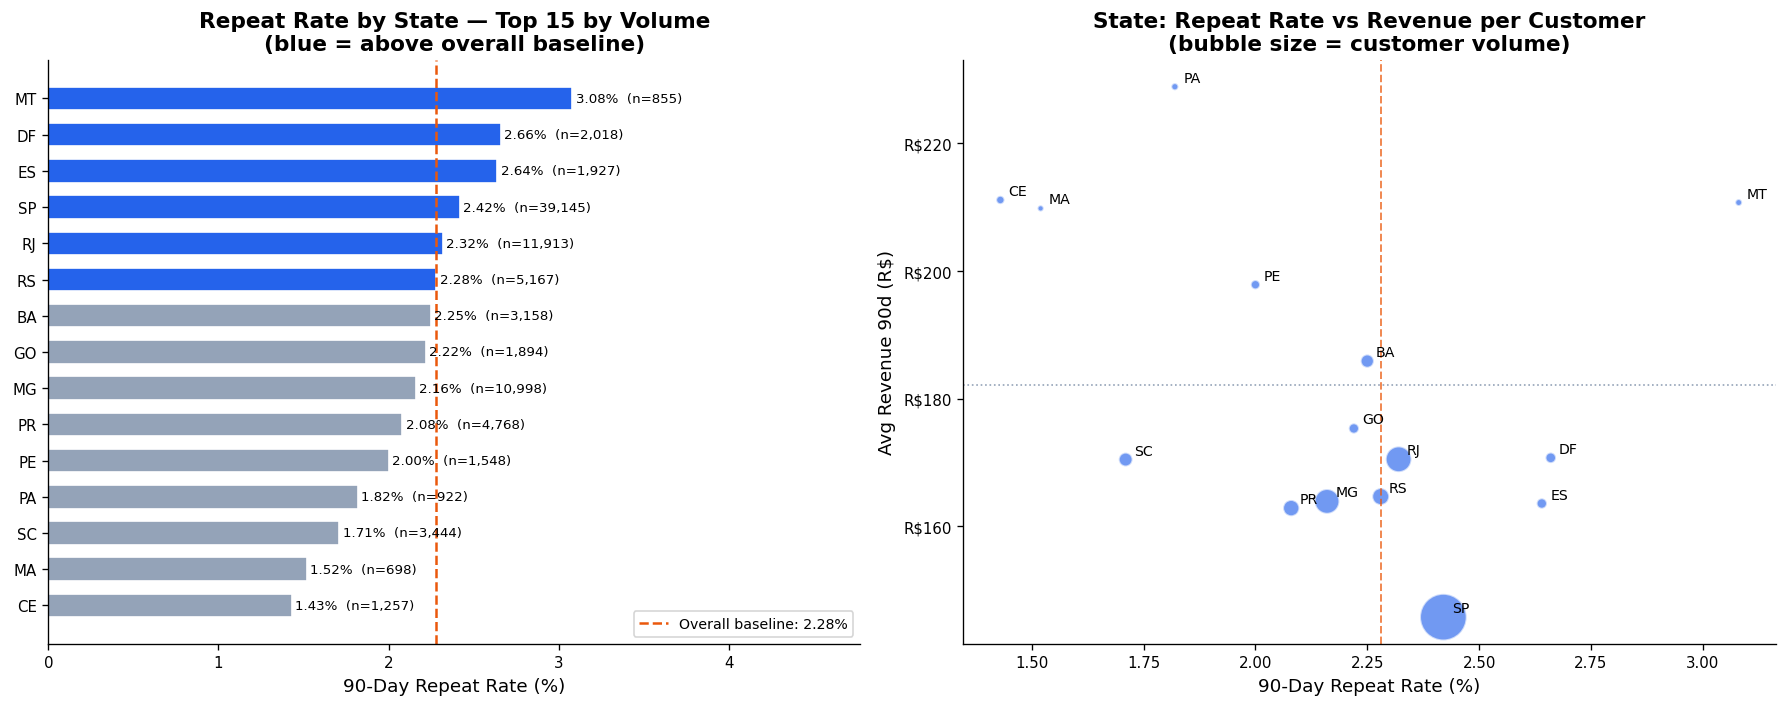

Saved: images/segment_by_geography.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ── Left: repeat rate horizontal bar ─────────────────────────────────────────
ax1 = axes[0]
colors_g = [C_BLUE if r >= BASELINE_90D else C_GREY for r in geo_plot["rate_90d_pct"]]
bars1 = ax1.barh(geo_plot["segment_value"], geo_plot["rate_90d_pct"],
                 color=colors_g, height=0.65, edgecolor="white")
ax1.axvline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.5,
            label=f"Overall baseline: {BASELINE_90D}%")

for bar, (_, row) in zip(bars1, geo_plot.iterrows()):
    ax1.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height() / 2,
             f"{row.rate_90d_pct:.2f}%  (n={row.customers:,})",
             va="center", fontsize=8)

ax1.set_xlabel("90-Day Repeat Rate (%)")
ax1.set_title("Repeat Rate by State — Top 15 by Volume\n(blue = above overall baseline)")
ax1.legend(fontsize=8.5)
ax1.set_xlim(0, geo_plot["rate_90d_pct"].max() * 1.55)

# ── Right: revenue vs repeat rate scatter ────────────────────────────────────
ax2 = axes[1]
sizes_g = geo_df["customers"] / 50

sc = ax2.scatter(
    geo_df["rate_90d_pct"], geo_df["avg_rev_90d"],
    s=sizes_g, c=C_BLUE, alpha=0.65, edgecolors="white", linewidths=1.2,
)
ax2.axvline(BASELINE_90D, color=C_ORANGE, linestyle="--", linewidth=1.2, alpha=0.7)
ax2.axhline(geo_df["avg_rev_90d"].mean(), color=C_GREY, linestyle=":", linewidth=1.0)

for _, row in geo_df.iterrows():
    ax2.annotate(
        row["segment_value"],
        (row["rate_90d_pct"], row["avg_rev_90d"]),
        textcoords="offset points", xytext=(5, 3), fontsize=8.5,
    )

ax2.set_xlabel("90-Day Repeat Rate (%)")
ax2.set_ylabel("Avg Revenue 90d (R$)")
ax2.set_title("State: Repeat Rate vs Revenue per Customer\n(bubble size = customer volume)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R${int(x):,}"))

plt.tight_layout()
plt.savefig("../images/segment_by_geography.png", bbox_inches="tight")
plt.show()
print("Saved: images/segment_by_geography.png")


**Interpretation:**

| State | Customers | 90d Repeat Rate | Avg Revenue 90d |
|---|---|---|---|
| MT (Mato Grosso) | 855 | **3.08%** | R$211 |
| DF (Distrito Federal) | 2,018 | **2.66%** | R$171 |
| ES (Espírito Santo) | 1,927 | **2.64%** | R$164 |
| SP (São Paulo) | 39,145 | 2.42% | R$146 |
| RJ (Rio de Janeiro) | 11,913 | 2.32% | R$171 |
| CE (Ceará) | 1,257 | 1.43% | R$211 |
| SC (Santa Catarina) | 3,444 | 1.71% | R$170 |
| MA (Maranhão) | 698 | 1.52% | R$210 |

**Strong states:** MT, DF, and ES are the best-performing among mid-size states (1,000–5,000 customers). These states also tend to have higher average revenues.

**Large state performance:** SP (São Paulo, the largest state) is slightly above baseline at 2.42% — this is significant given its 39,145-customer size. A 1pp improvement in SP alone would convert ~750 additional customers to repeat buyers.

**Weaker states:** CE (1.43%), SC (1.71%), and MA (1.52%) are below baseline. These may reflect logistics challenges (longer delivery times in the North/Northeast), different product category mixes, or lower platform penetration.

**The revenue–repeat quadrant:** States in the top-right (high rate AND high revenue) are the most valuable. PA (Pará, northeast Brazil) and PE (Pernambuco) show lower repeat rates but higher average revenues — suggesting a higher-value but less-sticky customer base.

**Business implication:** SP is the highest-priority state for retention investment due to pure scale. DF/ES/MT are worth study as benchmark states — understanding what drives their stronger retention could inform platform changes that benefit all states.


---

## 8. Segment Comparison Summary

This section brings together all seven dimensions into a single ranked view, showing which segments deviate most from the overall baseline — both above (opportunity to scale) and below (candidates for intervention).

**Effect size** = segment repeat rate minus the overall 90-day baseline (2.28%). Positive = outperforms; negative = underperforms.


In [17]:
# Build a summary DataFrame of best and worst buckets per dimension
BASELINE = BASELINE_90D  # 2.28%

def get_extremes(dim, min_customers=200, label_col="segment_value"):
    df = get_segment(dim, min_customers=min_customers)
    df = df[~df[label_col].isin(["unknown", "null_payment"])].copy()
    df["effect_pp"] = df["rate_90d_pct"] - BASELINE
    best = df.nlargest(1, "rate_90d_pct").iloc[0]
    worst = df.nsmallest(1, "rate_90d_pct").iloc[0]
    return {
        "Dimension": dim.replace("first_", "").replace("_bucket", "").replace("_", " ").title(),
        "Best Segment": best[label_col],
        "Best Rate (%)": best["rate_90d_pct"],
        "Best Effect (pp)": round(best["effect_pp"], 2),
        "Best n": int(best["customers"]),
        "Worst Segment": worst[label_col],
        "Worst Rate (%)": worst["rate_90d_pct"],
        "Worst Effect (pp)": round(worst["effect_pp"], 2),
        "Worst n": int(worst["customers"]),
    }

dims = [
    "first_total_items_bucket",
    "first_primary_category",
    "first_order_value_bucket",
    "first_payment_type",
    "first_delivery_speed_bucket",
    "first_review_score_bucket",
    "first_customer_state",
]

summary_rows = [get_extremes(d) for d in dims]
summary_df = pd.DataFrame(summary_rows)
summary_df = summary_df.sort_values("Best Effect (pp)", ascending=False)
summary_df


,Dimension,Best Segment,Best Rate (%),Best Effect (pp),Best n,Worst Segment,Worst Rate (%),Worst Effect (pp),Worst n
1,Primary Category,home_appliances,7.69,5.41,675,cool_stuff,0.92,-1.36,3457
0,Total Items,6+ items,5.38,3.10,235,1 item,2.15,-0.13,84151
6,Customer State,MT,3.08,0.80,855,SE,1.17,-1.11,327
3,Payment Type,voucher,3.07,0.79,1409,debit_card,2.17,-0.11,1441
2,Order Value,low (<50),2.46,0.18,15916,high (150-399),1.98,-0.30,24650
4,Delivery Speed,fast (<=7d),2.36,0.08,29513,very_slow (>30d),1.96,-0.32,4184
5,Review Score,high (4-5),2.28,0.00,73161,mid (3),2.23,-0.05,7669


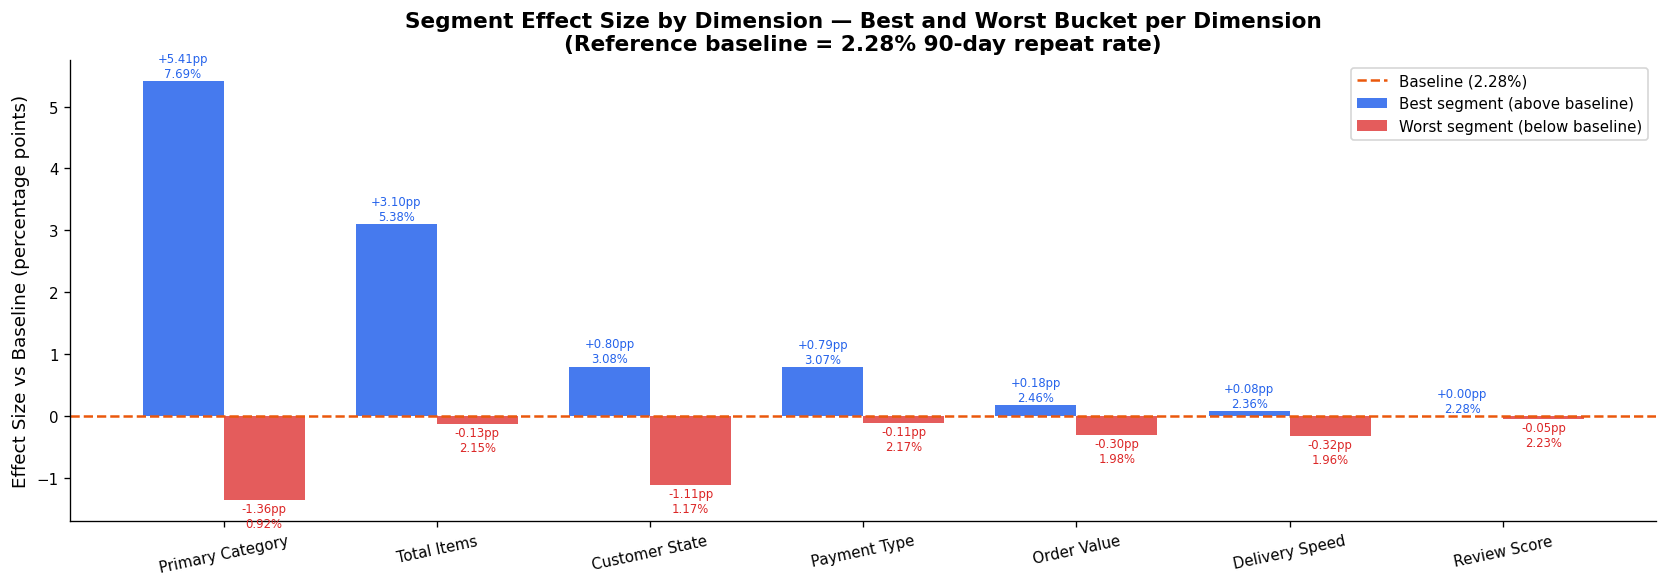

Saved: images/segment_summary_comparison.png


In [18]:
fig, ax = plt.subplots(figsize=(14, 5))

dims_labels  = summary_df["Dimension"].tolist()
best_effects = summary_df["Best Effect (pp)"].tolist()
worst_effects= summary_df["Worst Effect (pp)"].tolist()
x_dim = np.arange(len(dims_labels))
bar_w = 0.38

b1 = ax.bar(x_dim - bar_w / 2, best_effects, width=bar_w, color=C_BLUE,
            alpha=0.85, label="Best segment (above baseline)")
b2 = ax.bar(x_dim + bar_w / 2, worst_effects, width=bar_w, color=C_RED,
            alpha=0.75, label="Worst segment (below baseline)")

ax.axhline(0, color=C_ORANGE, linewidth=1.5, linestyle="--",
           label=f"Baseline ({BASELINE}%)")

for bar, val, row in zip(b1, best_effects,
                          summary_df[["Best Segment","Best Rate (%)"]].itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
            f"+{val:.2f}pp\n{row._2:.2f}%",
            ha="center", va="bottom", fontsize=7, color=C_BLUE)

for bar, val, row in zip(b2, worst_effects,
                          summary_df[["Worst Segment","Worst Rate (%)"]].itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() - 0.03,
            f"{val:.2f}pp\n{row._2:.2f}%",
            ha="center", va="top", fontsize=7, color=C_RED)

ax.set_xticks(x_dim)
ax.set_xticklabels(dims_labels, rotation=12)
ax.set_ylabel("Effect Size vs Baseline (percentage points)")
ax.set_title(
    "Segment Effect Size by Dimension — Best and Worst Bucket per Dimension\n"
    f"(Reference baseline = {BASELINE}% 90-day repeat rate)"
)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../images/segment_summary_comparison.png", bbox_inches="tight")
plt.show()
print("Saved: images/segment_summary_comparison.png")


**Reading this chart:** Each bar pair shows the best-performing (blue) and worst-performing (red) bucket within that dimension, measured as percentage-point deviation from the 2.28% overall baseline. Taller blue bars = stronger positive signal; deeper red bars = stronger negative signal.

**Strongest positive signals (above baseline):**
1. **Total Items Bucket** — the 6+ item segment is +3.10pp above baseline. Strongest single signal in the dataset.
2. **Primary Category** — home_appliances (+5.41pp), fashion/lifestyle categories well above baseline.
3. **Payment Type** — voucher customers are +0.79pp above baseline.

**Strongest negative signals (below baseline):**
1. **Primary Category** — electronics, cool_stuff, watches/gifts are farthest below baseline.
2. **Total Items Bucket** — 1-item buyers are 0.13pp below baseline (modest but large-volume effect).
3. **Delivery Speed** — very slow delivery is 0.32pp below baseline.

**Dimensions with the smallest spread (least discriminating):**
- **Review Score** — the spread between best and worst is tiny (~0.05pp). Review score is NOT a useful targeting signal in this dataset.
- **Delivery Speed** — modest spread; not the primary driver of repeat behaviour.


---

## 9. Business Implications

Drawing together all seven dimensions, six data-backed implications for product and growth teams:


In [19]:
# Final reference table: all dimensions at a glance
final_summary = pd.read_sql(
    """
    SELECT
        segment_dimension,
        segment_value,
        customers,
        ROUND(repeat_rate_90d * 100, 2)  AS rate_90d_pct,
        ROUND(avg_revenue_90d, 2)        AS avg_rev_90d,
        ROUND(avg_days_to_second_order, 0) AS avg_days_to_return
    FROM spm_mat
    WHERE customers >= 200
      AND segment_value NOT IN ('unknown', 'null_payment')
    ORDER BY segment_dimension, repeat_rate_90d DESC
    """,
    conn,
)
print("Full segment reference table (200+ customers, sorted by dimension then rate):")
print(final_summary.to_string(index=False))


Full segment reference table (200+ customers, sorted by dimension then rate):
          segment_dimension                           segment_value  customers  rate_90d_pct  avg_rev_90d  avg_days_to_return
       first_customer_state                                      MT        855          3.08       210.74                60.0
       first_customer_state                                      RO        230          3.08       244.36                88.0
       first_customer_state                                      DF       2018          2.66       170.73                59.0
       first_customer_state                                      ES       1927          2.64       163.57                74.0
       first_customer_state                                      MS        681          2.54       197.20                40.0
       first_customer_state                                      SP      39145          2.42       145.76                80.0
       first_customer_state             

### Key Business Implications

---

**1. First-order basket size is the single strongest predictor — and it's actionable**
Customers who buy 6+ items in their first order return at **5.38%** vs **2.15%** for single-item buyers — a 2.5× higher rate. Even a nudge from 1 item to 2 items (2.15% → 3.15%) represents a **47% relative improvement** in retention probability. Tactics: "Frequently bought together" recommendations, first-order bundle discounts, minimum-spend incentives for basket top-up.

---

**2. Target category matters — build category-aware re-engagement**
Customers who first buy in `bed_bath_table` (4.02%), `furniture_decor` (3.49%), or `fashion_bags_accessories` (4.58%) are already ~75% more likely to return than `electronics` (1.08%) or `watches_gifts` (1.59%) buyers. Post-purchase emails should be category-specific: replenishment-category buyers need quick follow-up (7–14 days); big-ticket buyers need longer-horizon campaigns (60–90 days).

---

**3. Low first-order value ≠ low loyalty — don't neglect small-basket buyers**
Counter to common intuition, low-value buyers (< R$50) have a **2.46%** repeat rate — slightly above the overall baseline and above high-value buyers (1.98%). Their 90-day revenue is low (R$39) but they are a large group (15,916 customers). Many are exploration purchases: the customer is testing the platform cheaply before committing to larger orders. A strong onboarding experience and early re-engagement can convert these trial buyers into repeat customers.

---

**4. Late delivery is a soft retention drag — recovery is worth the cost**
Customers who received a late first delivery repeat at **2.05%** vs **2.30%** for customers who received early deliveries — a **0.25pp gap**. With 7,428 affected customers, this represents approximately 19 fewer repeat buyers than if delivery had been on time. A proactive post-purchase apology or R$15 discount voucher for late-delivery customers would likely close a material portion of this gap at low cost.

---

**5. Voucher customers are a high-retention, low-margin risk**
Voucher buyers have the highest repeat rate (3.07%) but the lowest average 90-day revenue (R$108) and return slowest (86 days). They are price-motivated and likely wait for another discount. For a business that wants to grow volume, re-engaging voucher users with a follow-up offer is effective. For a business focused on margin, monitor whether voucher users ever graduate to full-price purchases.

---

**6. Review scores should not be used as a churn filter — but still merit recovery outreach**
Customers with 1–2 star reviews have identical 90-day repeat rates to satisfied customers (2.28%) and actually return 24 days faster on average. Review score does NOT identify non-returners. However, dissatisfied customers who return without intervention may return frustrated — potentially generating another low review and increasing churn later. Service recovery (apology, resolution offer) is justified not to save the first-return, but to improve the quality of that return and build long-term loyalty.

---


---

*Next notebook: `05_clv_and_churn_signals.ipynb` — CLV band analysis, churn signal prevalence, and at-risk customer profiling.*


In [20]:
conn.close()
print("Database connection closed.")


Database connection closed.
